In [8]:
import sys
from pathlib import Path

root = Path.cwd().resolve()
while root != root.parent and not (root / "shared").exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from shared.paths import get_experiment_paths
from shared.visualization import show_grid, save_grid

import torch
device = "cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

In [9]:
demo_paths = get_experiment_paths("04_latent_interpolation")
out_dir = demo_paths.exp_dir / "outputs"
(out_dir / "dcgan").mkdir(parents=True, exist_ok=True)
(out_dir / "cdcgan").mkdir(parents=True, exist_ok=True)
out_dir

WindowsPath('D:/Projects/GANs/experiments/04_latent_interpolation/outputs')

In [10]:
def latest_ckpt(models_dir):
    ckpts = sorted(Path(models_dir).glob("ckpt_epoch_*.pth"))
    if not ckpts:
        raise FileNotFoundError(f"No ckpt_epoch_*.pth found in {models_dir}")
    return ckpts[-1]

In [11]:
import torch.nn as nn

class DCGAN_Generator(nn.Module):
    def __init__(self, z_dim=100, img_channels=1, feat=64):
        super().__init__()
        self.net = nn.Sequential(
            nn.ConvTranspose2d(z_dim, feat*4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(feat*4),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*4, feat*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat*2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*2, feat, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat),
            nn.ReLU(True),

            nn.Conv2d(feat, img_channels, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, z):
        return self.net(z)

In [12]:
dcgan_paths = get_experiment_paths("02_dcgan")
ckpt_path = latest_ckpt(dcgan_paths.models_dir)
ckpt = torch.load(ckpt_path, map_location=device)

z_dim = ckpt.get("z_dim", 100)
feat = ckpt.get("feat", 64)

G = DCGAN_Generator(z_dim=z_dim, feat=feat).to(device)
G.load_state_dict(ckpt["G"])
G.eval()

print("Loaded:", ckpt_path.name, "| z_dim:", z_dim, "| feat:", feat)

Loaded: ckpt_epoch_020.pth | z_dim: 100 | feat: 64


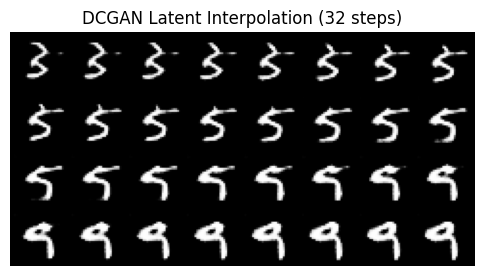

In [19]:
@torch.no_grad()
def lerp(z1, z2, steps):
    alphas = torch.linspace(0, 1, steps, device=device).view(-1, 1, 1, 1)
    return (1 - alphas) * z1 + alphas * z2

steps = 32  # more steps = smoother morph
z1 = torch.randn(1, z_dim, 1, 1, device=device)
z2 = torch.randn(1, z_dim, 1, 1, device=device)

z_interp = lerp(z1, z2, steps)      # (steps, z_dim, 1, 1)
imgs = G(z_interp)                  # (steps, 1, 28, 28)

show_grid(imgs, title=f"DCGAN Latent Interpolation ({steps} steps)", nrow=8)

save_grid(imgs, out_dir / "dcgan" / f"interp_{ckpt_path.stem}.png", nrow=8)

In [14]:
class CGenerator(nn.Module):
    def __init__(self, z_dim=100, num_classes=10, embed_dim=100, img_channels=1, feat=64):
        super().__init__()
        self.embed = nn.Embedding(num_classes, embed_dim)
        in_ch = z_dim + embed_dim

        self.net = nn.Sequential(
            nn.ConvTranspose2d(in_ch, feat*4, 7, 1, 0, bias=False),
            nn.BatchNorm2d(feat*4),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*4, feat*2, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat*2),
            nn.ReLU(True),

            nn.ConvTranspose2d(feat*2, feat, 4, 2, 1, bias=False),
            nn.BatchNorm2d(feat),
            nn.ReLU(True),

            nn.Conv2d(feat, img_channels, 3, 1, 1),
            nn.Tanh()
        )

    def forward(self, z, y):
        y_emb = self.embed(y).unsqueeze(2).unsqueeze(3)
        x = torch.cat([z, y_emb], dim=1)
        return self.net(x)

In [15]:
cdcgan_paths = get_experiment_paths("03_cdcgan")
ckpt_path_c = latest_ckpt(cdcgan_paths.models_dir)
ckpt_c = torch.load(ckpt_path_c, map_location=device)

z_dim_c = ckpt_c.get("z_dim", 100)
feat_c = ckpt_c.get("feat", 64)
embed_dim_c = ckpt_c.get("embed_dim", 100)
num_classes_c = ckpt_c.get("num_classes", 10)

Gc = CGenerator(z_dim=z_dim_c, num_classes=num_classes_c, embed_dim=embed_dim_c, feat=feat_c).to(device)
Gc.load_state_dict(ckpt_c["G"])
Gc.eval()

print("Loaded:", ckpt_path_c.name)

Loaded: ckpt_epoch_020.pth


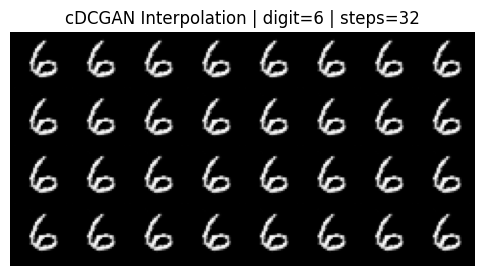

In [16]:
steps = 32
digit = 6

z1 = torch.randn(1, z_dim_c, 1, 1, device=device)
z2 = torch.randn(1, z_dim_c, 1, 1, device=device)
z_interp = lerp(z1, z2, steps)

y = torch.full((steps,), digit, device=device, dtype=torch.long)

with torch.no_grad():
    imgs = Gc(z_interp, y)

show_grid(imgs, title=f"cDCGAN Interpolation | digit={digit} | steps={steps}", nrow=8)
save_grid(imgs, out_dir / "cdcgan" / f"interp_digit{digit}_{ckpt_path_c.stem}.png", nrow=8)

In [17]:
import imageio.v2 as imageio
import numpy as np

def tensor_to_uint8(img):
    # img: (1,28,28) in [-1,1]
    x = img.detach().cpu()
    x = (x + 1) / 2              # [0,1]
    x = (x * 255).clamp(0,255).byte()
    return x.squeeze(0).numpy()

gif_path = out_dir / "dcgan" / f"interp_{ckpt_path.stem}.gif"
frames = [tensor_to_uint8(imgs[i]) for i in range(imgs.size(0))]
imageio.mimsave(gif_path, frames, duration=0.08)
gif_path

WindowsPath('D:/Projects/GANs/experiments/04_latent_interpolation/outputs/dcgan/interp_ckpt_epoch_020.gif')